In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [6]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [ ]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20
rng = np.random.default_rng(4)

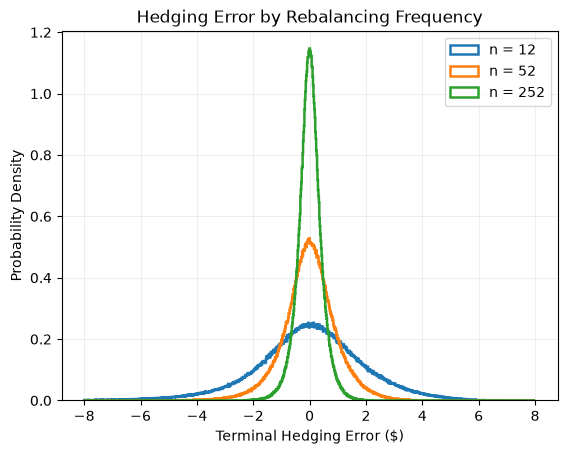

In [ ]:
n_values = [12,52,252]
M = 1000000

for n in n_values:

    t_array = np.linspace(0, T, n+1)
    delta_t = T/n

    randoms = rng.normal(0, np.sqrt(delta_t), size = (M, n))
    zeros = np.array([[0]] * M)

    brownian_increments = np.concatenate((zeros, randoms), axis = 1)
    brownian = np.cumsum(brownian_increments, axis = 1)

    diffusion = np.multiply(sigma, brownian)
    drift = np.multiply(t_array, (r - 0.5 * (sigma**2)))

    price_factor = np.exp(drift + diffusion)
    prices = np.multiply(S0, price_factor)

    tau = 1 - t_array[:-1]
    d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
    delta = norm.cdf(d1)

    option_premium, _ = black_scholes_price(S0, K, T, r, sigma)


    delta_change = np.diff(delta, axis = 1)
    interest = np.exp(r * tau[1:])

    rebalance_costs = delta_change * prices[:, 1:-1]
    adjusted_costs = rebalance_costs * interest
    total_cost = np.sum(adjusted_costs, axis=1)

    initial_cash = option_premium - (prices.T[0] * delta.T[0])
    initial_cash *= np.exp(r * T)

    terminal_cash = initial_cash - total_cost

    portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]

    call_payoff = np.maximum(prices.T[-1] - K, 0)

    error = portfolio_value - call_payoff

    plt.hist(error,
         bins=np.linspace(-8, 8, 1000),
         density=True,
         histtype="step",
         linewidth=1.8,
         label=f"n = {n}")

plt.xlabel("Terminal Hedging Error ($)")
plt.ylabel("Probability Density")
plt.title("Hedging Error by Rebalancing Frequency")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


n =    5 | Mean = +0.054836 | RMSE = 2.867421
n =   12 | Mean = +0.012524 | RMSE = 1.938366
n =   20 | Mean = -0.014948 | RMSE = 1.483217
n =   52 | Mean = +0.007880 | RMSE = 0.949482
n =  100 | Mean = -0.001643 | RMSE = 0.686937
n =  252 | Mean = -0.002142 | RMSE = 0.434668
n =  500 | Mean = +0.003231 | RMSE = 0.310341
n = 1000 | Mean = -0.000524 | RMSE = 0.218785


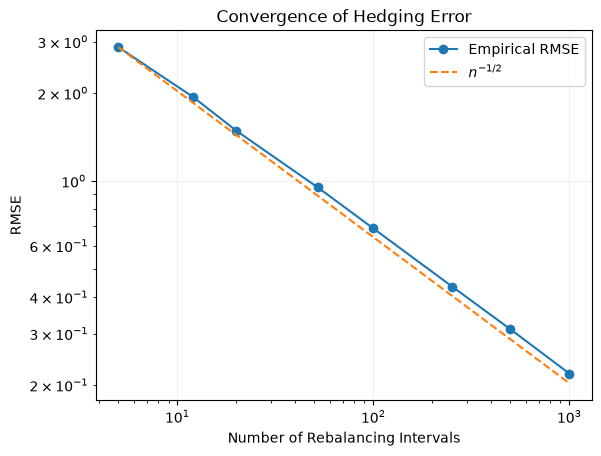

In [28]:
n_values = [5,12,20,52,100,252,500,1000]
rmse_values = []
mean_errors = []

M = 10000

for n in n_values:

    t_array = np.linspace(0, T, n+1)
    delta_t = T/n

    randoms = rng.normal(0, np.sqrt(delta_t), size = (M, n))
    zeros = np.array([[0]] * M)

    brownian_increments = np.concatenate((zeros, randoms), axis = 1)
    brownian = np.cumsum(brownian_increments, axis = 1)

    diffusion = np.multiply(sigma, brownian)
    drift = np.multiply(t_array, (r - 0.5 * (sigma**2)))

    price_factor = np.exp(drift + diffusion)
    prices = np.multiply(S0, price_factor)

    tau = 1 - t_array[:-1]
    d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
    delta = norm.cdf(d1)

    option_premium, _ = black_scholes_price(S0, K, T, r, sigma)


    delta_change = np.diff(delta, axis = 1)
    interest = np.exp(r * tau[1:])

    rebalance_costs = delta_change * prices[:, 1:-1]
    adjusted_costs = rebalance_costs * interest
    total_cost = np.sum(adjusted_costs, axis=1)

    initial_cash = option_premium - (prices.T[0] * delta.T[0])
    initial_cash *= np.exp(r * T)

    terminal_cash = initial_cash - total_cost

    portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]

    call_payoff = np.maximum(prices.T[-1] - K, 0)

    error = portfolio_value - call_payoff

    rmse = np.sqrt(np.mean(error**2))
    rmse_values.append(rmse)

    mean_errors.append(np.mean(error))

for n, mean, rmse in zip(n_values, mean_errors, rmse_values):
    print(f"n = {n:4d} | Mean = {mean:+.6f} | RMSE = {rmse:.6f}")

n_array = np.array(n_values)
reference = rmse_values[0] * (n_array / n_array[0])**(-0.5)

plt.loglog(n_values, rmse_values, 'o-', label="Empirical RMSE")
plt.loglog(n_values, reference, '--', label=r"$n^{-1/2}$")

plt.xlabel("Number of Rebalancing Intervals")
plt.ylabel("RMSE")
plt.title("Convergence of Hedging Error")
plt.grid(alpha=0.2)
plt.legend()
plt.show()


